<a href="https://colab.research.google.com/github/dhrishithagcd24-collab/DLG_LAB/blob/main/DLG_Lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving example.webp to example (4).webp
Image loaded successfully: (521, 800, 3)


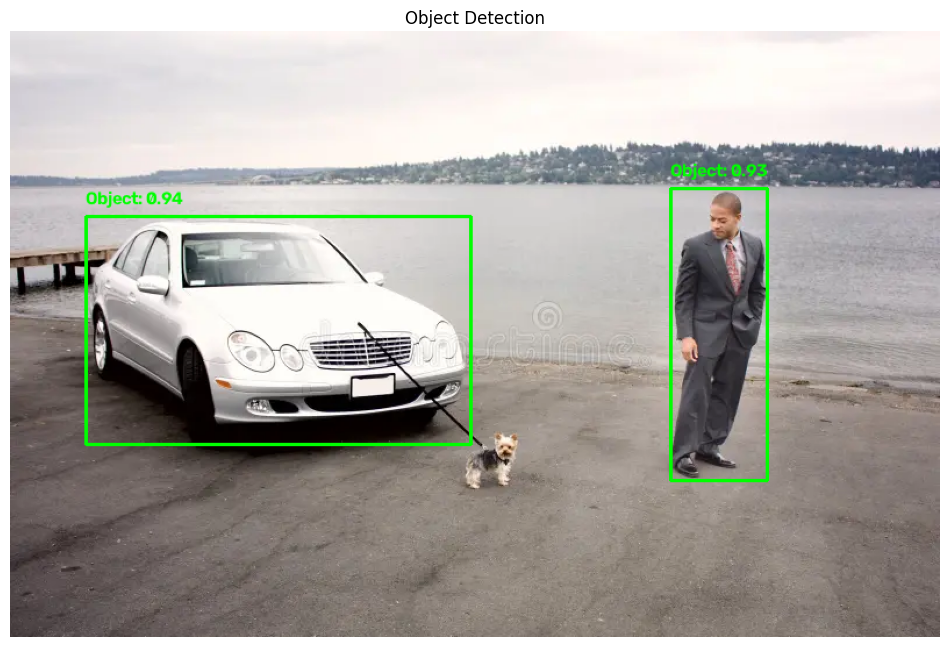

In [58]:

import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

# Load image
image = cv2.imread(image_path)

if image is None:
    raise ValueError(f"Could not load image: {image_path}")

print("Image loaded successfully:", image.shape)

# Detect objects and draw bounding boxes
def detect_objects_with_boxes(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    orig_image = image.copy()

    # Preprocess image
    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run object detector
    detections = detector(input_tensor)

    # Extract detection results
    num_detections = int(detections.pop("num_detections"))
    detections = {
        key: value[0, :num_detections].numpy()
        for key, value in detections.items()
    }

    # Draw bounding boxes
    height, width, _ = orig_image.shape

    for i in range(num_detections):
        score = detections["detection_scores"][i]

        if score < 0.5:
            continue

        box = detections["detection_boxes"][i]
        ymin, xmin, ymax, xmax = box

        x1 = int(xmin * width)
        y1 = int(ymin * height)
        x2 = int(xmax * width)
        y2 = int(ymax * height)

        cv2.rectangle(
            orig_image, (x1, y1), (x2, y2), (0, 255, 0), 2
        )

        label = f"Object: {score:.2f}"
        cv2.putText(
            orig_image, label, (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
        )

    return orig_image

# Run detection
result_image = detect_objects_with_boxes(image_path, detector)

# Display output in notebook
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Object Detection")
plt.show()


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving example.webp to example (2).webp


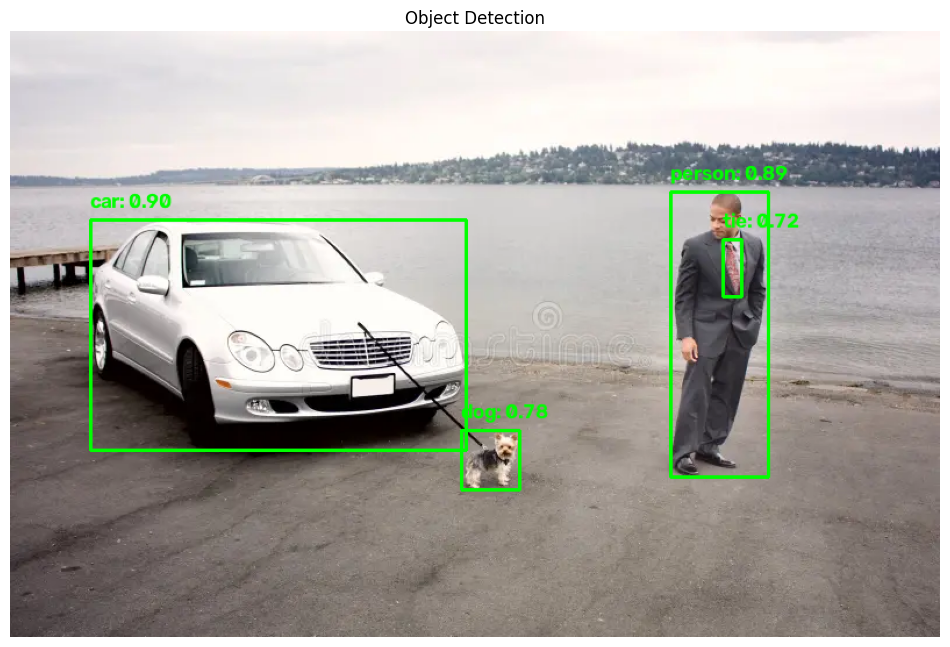

In [ ]:

# Install required packages (run in Google Colab)
!pip -q install ultralytics

import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# Upload an image
uploaded = files.upload()
img_path = next(iter(uploaded.keys()))

# Load image
img = cv2.imread(img_path)

if img is None:
    raise ValueError(f"Could not load image: {img_path}")

# Load a pretrained object detection model
# Downloads pretrained weights on the first run
model = YOLO("yolov8n.pt")

# Run object detection
results = model.predict(
    source=img,
    conf=0.5,
    verbose=False
)

# Draw bounding boxes and class labels
result_img = img.copy()

for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        label = f"{model.names[class_id]}: {confidence:.2f}"

        cv2.rectangle(
            result_img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result_img,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

# Display the result (works in Colab and Jupyter)
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.title("Object Detection")
plt.axis("off")
plt.show()
